# Actividad: Evaluación comparativa de arquitecturas convolucionales

Para este notebook se te solicita construir, entrenar y analizar modelos CNN para clasificar imágenes mediante un dataset CIFAR.

**Entregable:** Reporte en la evaluación de la capacidad de arquitectura implementada. Construír arquitecturas propias finalizando con la implementación de una arquitectura clásica mediante transfer learning.


## Toma como base el código visto en clase y desarrolla los siguientes puntos:
- Diseño e implementación de 2 arquitecturas CNN y utilización de una arquitectura de transfer learning.

- Buen uso de data augmentation y regularización.

- Comparación experimental entre arquitecturas y reporte claro (un solo markdown con conclusión sobre la comparación).





In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)
print('TensorFlow', tf.__version__)

I0000 00:00:1793801288.361977     686 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793801290.341019     686 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## Datos: CIFAR-10

CIFAR-10 contiene 60,000 imágenes a color de 32×32 píxeles en 10 clases (50,000 de entrenamiento y 10,000 de prueba). Separamos las últimas 5,000 imágenes de entrenamiento como conjunto de validación, el mismo para los tres modelos, para que la comparación sea justa. El conjunto de prueba solo se usa al final.

*Nota sobre los datos:* en mi ejecución el servidor oficial de CIFAR-10 no estaba disponible, así que usé una copia del mismo conjunto tomada de un repositorio público (las mismas 60,000 imágenes y etiquetas, guardadas en formato JPG). Si se ejecuta el notebook con acceso a internet, carga los datos oficiales con `keras.datasets.cifar10` y los resultados pueden variar ligeramente.

Sin acceso al servidor oficial de CIFAR-10; se usa la copia local cifar10_local.npz


Entrenamiento: (45000, 32, 32, 3) | Validación: (5000, 32, 32, 3) | Prueba: (10000, 32, 32, 3)


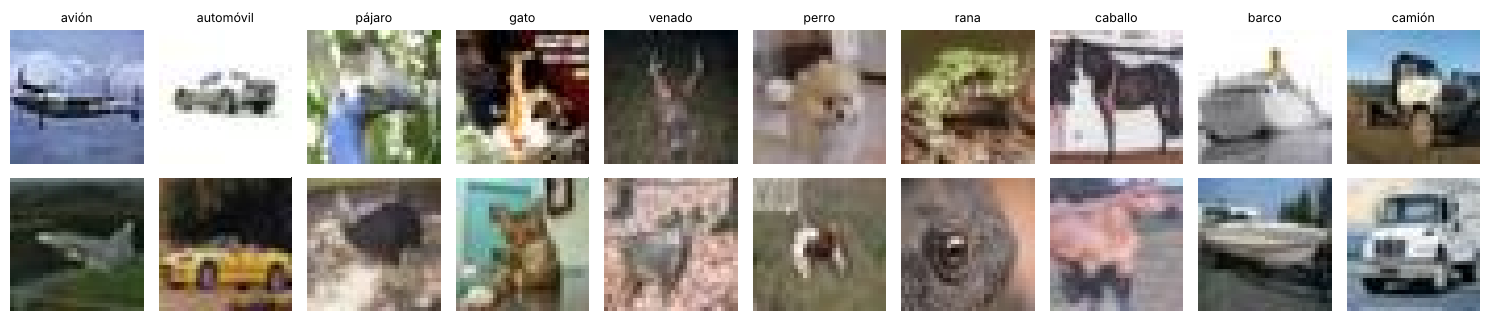

In [2]:
def cargar_cifar10():
    try:
        datos = keras.datasets.cifar10.load_data()
        print('Fuente de datos: keras.datasets.cifar10 (servidor oficial)')
        return datos
    except Exception as e:
        # Respaldo: copia local de CIFAR-10 (mismas imágenes y etiquetas) por si no hay acceso al servidor oficial
        print('Sin acceso al servidor oficial de CIFAR-10; se usa la copia local cifar10_local.npz')
        d = np.load('cifar10_local.npz')
        return (d['x_train'], d['y_train']), (d['x_test'], d['y_test'])

(x_train_full, y_train_full), (x_test, y_test) = cargar_cifar10()
clases = ['avión', 'automóvil', 'pájaro', 'gato', 'venado', 'perro', 'rana', 'caballo', 'barco', 'camión']

x_train, y_train = x_train_full[:45000], y_train_full[:45000]
x_val, y_val = x_train_full[45000:], y_train_full[45000:]

y_train_oh = keras.utils.to_categorical(y_train, 10)
y_val_oh = keras.utils.to_categorical(y_val, 10)
y_test_oh = keras.utils.to_categorical(y_test, 10)

print('Entrenamiento:', x_train.shape, '| Validación:', x_val.shape, '| Prueba:', x_test.shape)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    idx = np.where(y_train.ravel() == c)[0][:2]
    for r in range(2):
        axes[r, c].imshow(x_train[idx[r]]); axes[r, c].axis('off')
    axes[0, c].set_title(clases[c], fontsize=9)
plt.tight_layout(); plt.show()

**Data augmentation.** Definimos un bloque de aumento de datos que se aplica solo durante el entrenamiento: volteo horizontal, desplazamientos de hasta 10 % y rotaciones pequeñas. Así cada época la red ve variaciones de las mismas imágenes y aprende rasgos que no dependen de la posición exacta del objeto.

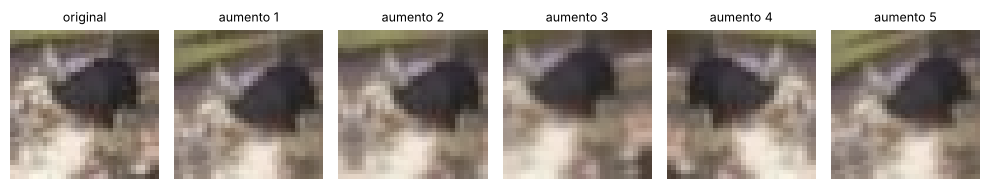

In [3]:
aumento = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.05),
], name='aumento')

ejemplo = x_train[7:8]
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
axes[0].imshow(ejemplo[0]); axes[0].set_title('original', fontsize=9)
for i in range(1, 6):
    axes[i].imshow(np.clip(aumento(ejemplo, training=True)[0].numpy(), 0, 255).astype('uint8'))
    axes[i].set_title(f'aumento {i}', fontsize=9)
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

## Definiciones de modelos

In [4]:
# Arquitectura 1: CNN sencilla
# Tres bloques Conv(3x3) + MaxPooling con 32, 64 y 128 filtros, y una capa densa de 128 neuronas.
# Regularización: data augmentation y Dropout(0.5) antes de la capa densa.
def crear_cnn_sencilla():
    return keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        aumento,
        layers.Rescaling(1/255.),
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ], name='cnn_sencilla')

cnn_sencilla = crear_cnn_sencilla()
cnn_sencilla.summary()

Model: "cnn_sencilla"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento (Sequential)            │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Arquitectura 2: CNN profunda estilo VGG
# Tres bloques de DOS convoluciones 3x3 (32, 64 y 128 filtros) con BatchNormalization.
# Regularización: data augmentation, L2 en los filtros, Dropout creciente por bloque (0.2, 0.3, 0.4)
# y GlobalAveragePooling en lugar de Flatten para reducir parámetros.
def bloque_conv(filtros, dropout):
    capas = []
    for _ in range(2):
        capas += [layers.Conv2D(filtros, 3, padding='same', use_bias=False,
                                kernel_regularizer=regularizers.l2(1e-4)),
                  layers.BatchNormalization(),
                  layers.Activation('relu')]
    capas += [layers.MaxPooling2D(), layers.Dropout(dropout)]
    return capas

def crear_cnn_profunda():
    return keras.Sequential(
        [layers.Input(shape=(32, 32, 3)), aumento, layers.Rescaling(1/255.)]
        + bloque_conv(32, 0.2) + bloque_conv(64, 0.3) + bloque_conv(128, 0.4)
        + [layers.GlobalAveragePooling2D(),
           layers.Dense(128, activation='relu'),
           layers.Dropout(0.5),
           layers.Dense(10, activation='softmax')],
        name='cnn_profunda')

cnn_profunda = crear_cnn_profunda()
cnn_profunda.summary()

Model: "cnn_profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento (Sequential)            │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [6]:
# Arquitectura 3: transfer learning con VGG16 preentrenada en ImageNet
# Se congela la base convolucional (14.7 millones de parámetros) y solo se entrena una cabeza densa nueva.
# Estrategia de extracción de características: VGG16 procesa una sola vez las imágenes (originales y una
# versión aumentada) y la cabeza aprende sobre esos vectores de 512 rasgos. Regularización: Dropout(0.5).
base_vgg16 = VGG16(include_top=False, weights='imagenet', input_shape=(32, 32, 3))
base_vgg16.trainable = False

cabeza_tl = keras.Sequential([
    layers.Input(shape=base_vgg16.output_shape[1:]),
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax'),
], name='cabeza_vgg16')

# Modelo completo (imagen -> preprocesamiento VGG16 -> base congelada -> cabeza), usado para evaluar
entrada = keras.Input(shape=(32, 32, 3))
salida = cabeza_tl(base_vgg16(preprocess_input(entrada), training=False))
vgg16_tl = keras.Model(entrada, salida, name='vgg16_transfer')

print(f'Parámetros de la base VGG16 (congelados): {base_vgg16.count_params():,}')
cabeza_tl.summary()

Parámetros de la base VGG16 (congelados): 14,714,688


Model: "cabeza_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 133,898 (523.04 KB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento de modelos.

In [7]:
# Configuración común: Adam, entropía cruzada categórica, lotes de 128, misma validación para todos.
# EarlyStopping detiene el entrenamiento si la pérdida de validación deja de mejorar y recupera los mejores pesos;
# ReduceLROnPlateau reduce a la mitad la tasa de aprendizaje cuando el progreso se estanca.
def callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)]

historias, tiempos = {}, {}

cnn_sencilla.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
historias['cnn_sencilla'] = cnn_sencilla.fit(x_train, y_train_oh, validation_data=(x_val, y_val_oh),
                                             epochs=20, batch_size=128, callbacks=callbacks(), verbose=2)
tiempos['cnn_sencilla'] = time.time() - t0

Epoch 1/20


352/352 - 42s - 119ms/step - accuracy: 0.3692 - loss: 1.7234 - val_accuracy: 0.4760 - val_loss: 1.4840 - learning_rate: 0.0010


Epoch 2/20


352/352 - 37s - 105ms/step - accuracy: 0.4863 - loss: 1.4258 - val_accuracy: 0.5380 - val_loss: 1.3310 - learning_rate: 0.0010


Epoch 3/20


352/352 - 40s - 115ms/step - accuracy: 0.5348 - loss: 1.3003 - val_accuracy: 0.5880 - val_loss: 1.1741 - learning_rate: 0.0010


... (30 outputs left out)

Epoch 19/20


352/352 - 37s - 106ms/step - accuracy: 0.6997 - loss: 0.8492 - val_accuracy: 0.7264 - val_loss: 0.8030 - learning_rate: 5.0000e-04


Epoch 20/20


352/352 - 37s - 106ms/step - accuracy: 0.7052 - loss: 0.8417 - val_accuracy: 0.7294 - val_loss: 0.7700 - learning_rate: 5.0000e-04


In [8]:
cnn_profunda.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
historias['cnn_profunda'] = cnn_profunda.fit(x_train, y_train_oh, validation_data=(x_val, y_val_oh),
                                             epochs=15, batch_size=128, callbacks=callbacks(), verbose=2)
tiempos['cnn_profunda'] = time.time() - t0

Epoch 1/15


352/352 - 151s - 429ms/step - accuracy: 0.3728 - loss: 1.7543 - val_accuracy: 0.2220 - val_loss: 2.5110 - learning_rate: 0.0010


Epoch 2/15


352/352 - 144s - 408ms/step - accuracy: 0.4977 - loss: 1.4337 - val_accuracy: 0.4772 - val_loss: 1.6251 - learning_rate: 0.0010


Epoch 3/15


352/352 - 201s - 572ms/step - accuracy: 0.5481 - loss: 1.3096 - val_accuracy: 0.5712 - val_loss: 1.3008 - learning_rate: 0.0010


... (20 outputs left out)

Epoch 14/15


352/352 - 152s - 432ms/step - accuracy: 0.7204 - loss: 0.8847 - val_accuracy: 0.7090 - val_loss: 0.9460 - learning_rate: 5.0000e-04


Epoch 15/15


352/352 - 153s - 436ms/step - accuracy: 0.7244 - loss: 0.8738 - val_accuracy: 0.7442 - val_loss: 0.8325 - learning_rate: 5.0000e-04


In [9]:
# Transfer learning: extracción de características con la base VGG16 congelada
t0 = time.time()
def extraer(x, aumentar=False):
    feats = []
    for i in range(0, len(x), 500):
        lote = x[i:i+500].astype('float32')
        if aumentar:
            lote = aumento(lote, training=True)
        feats.append(base_vgg16(preprocess_input(lote), training=False).numpy())
    return np.concatenate(feats)

f_train = np.concatenate([extraer(x_train), extraer(x_train, aumentar=True)])   # originales + una copia aumentada
y_train_tl = np.concatenate([y_train_oh, y_train_oh])
f_val = extraer(x_val)
print('Características de entrenamiento:', f_train.shape)

cabeza_tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
historias['vgg16_transfer'] = cabeza_tl.fit(f_train, y_train_tl, validation_data=(f_val, y_val_oh),
                                            epochs=30, batch_size=128, callbacks=callbacks(), verbose=2)
tiempos['vgg16_transfer'] = time.time() - t0

# El modelo completo comparte los pesos de la cabeza ya entrenada; se compila solo para poder evaluarlo
vgg16_tl.compile(loss='categorical_crossentropy', metrics=['accuracy'])

Características de entrenamiento: (90000, 1, 1, 512)
Epoch 1/30


704/704 - 6s - 9ms/step - accuracy: 0.4270 - loss: 2.4972 - val_accuracy: 0.5952 - val_loss: 1.1986 - learning_rate: 0.0010


Epoch 2/30


704/704 - 5s - 7ms/step - accuracy: 0.5291 - loss: 1.3477 - val_accuracy: 0.6268 - val_loss: 1.0947 - learning_rate: 0.0010


Epoch 3/30


704/704 - 5s - 7ms/step - accuracy: 0.5644 - loss: 1.2388 - val_accuracy: 0.6500 - val_loss: 1.0515 - learning_rate: 0.0010


... (18 outputs left out)

Epoch 13/30


704/704 - 5s - 7ms/step - accuracy: 0.6894 - loss: 0.8605 - val_accuracy: 0.6756 - val_loss: 1.0245 - learning_rate: 2.5000e-04


Epoch 14/30


704/704 - 5s - 6ms/step - accuracy: 0.6981 - loss: 0.8382 - val_accuracy: 0.6788 - val_loss: 1.0257 - learning_rate: 1.2500e-04


## Estadística y gráficos

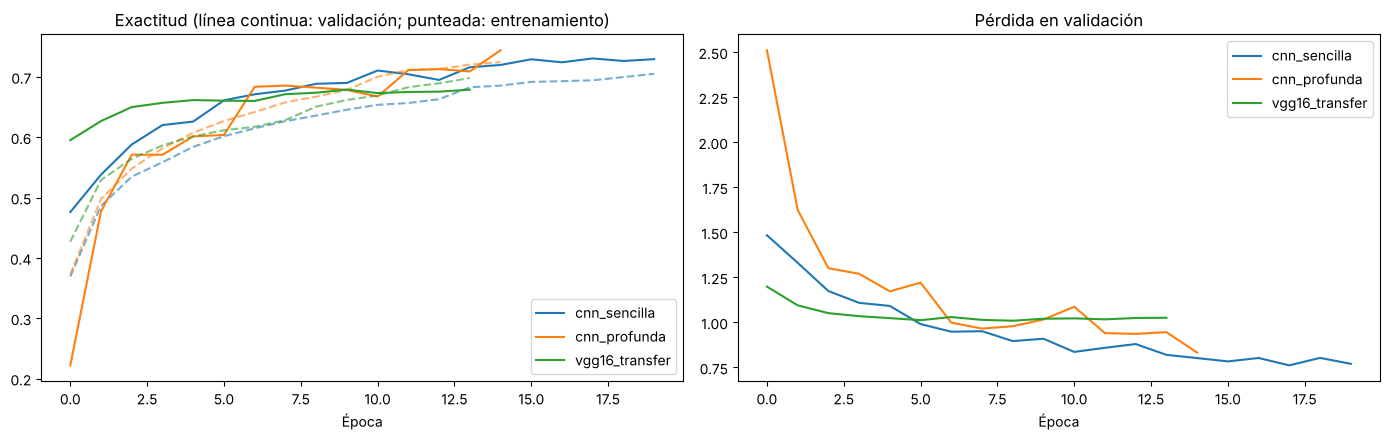

In [10]:
nombres = ['cnn_sencilla', 'cnn_profunda', 'vgg16_transfer']
modelos = {'cnn_sencilla': cnn_sencilla, 'cnn_profunda': cnn_profunda, 'vgg16_transfer': vgg16_tl}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n in nombres:
    h = historias[n].history
    l = axes[0].plot(h['accuracy'], linestyle='--', alpha=0.6)[0]
    axes[0].plot(h['val_accuracy'], color=l.get_color(), label=n)
    axes[1].plot(h['val_loss'], color=l.get_color(), label=n)
axes[0].set_title('Exactitud (línea continua: validación; punteada: entrenamiento)'); axes[0].set_xlabel('Época')
axes[1].set_title('Pérdida en validación'); axes[1].set_xlabel('Época')
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

In [11]:
filas, predicciones = [], {}
for n in nombres:
    m = modelos[n]
    proba = m.predict(x_test, batch_size=500, verbose=0)
    predicciones[n] = proba.argmax(axis=1)
    perdida, exactitud = m.evaluate(x_test, y_test_oh, batch_size=500, verbose=0)
    h = historias[n].history
    entrenables = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
    filas.append({'modelo': n,
                  'parámetros totales': m.count_params(),
                  'parámetros entrenables': entrenables,
                  'épocas': len(h['loss']),
                  'tiempo (min)': round(tiempos[n] / 60, 1),
                  'exactitud entrenamiento': round(max(h['accuracy']), 4),
                  'exactitud validación': round(max(h['val_accuracy']), 4),
                  'exactitud prueba': round(exactitud, 4),
                  'pérdida prueba': round(perdida, 4)})
tabla = pd.DataFrame(filas).set_index('modelo')
tabla

,parámetros totales,parámetros entrenables,épocas,tiempo (min),exactitud entrenamiento,exactitud validación,exactitud prueba,pérdida prueba
modelo,,,,,,,,
cnn_sencilla,356810,356810,20,13.2,0.7052,0.7306,0.7350,0.7622
cnn_profunda,306154,305258,15,38.8,0.7244,0.7442,0.7328,0.8382
vgg16_transfer,14848586,133898,14,9.1,0.6981,0.6790,0.6585,1.0355


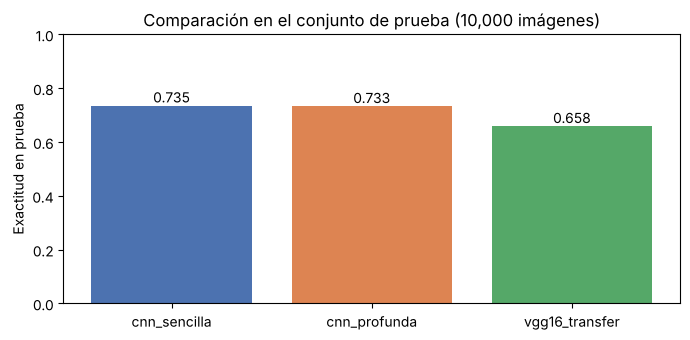

Exactitud por clase en prueba:


,cnn_sencilla,cnn_profunda,vgg16_transfer
avión,0.817,0.730,0.703
automóvil,0.848,0.851,0.742
pájaro,0.481,0.529,0.494
gato,0.497,0.335,0.488
venado,0.621,0.624,0.553
perro,0.611,0.633,0.590
rana,0.869,0.952,0.787
caballo,0.867,0.851,0.720
barco,0.863,0.910,0.767
camión,0.876,0.913,0.741


In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.bar(tabla.index, tabla['exactitud prueba'], color=['#4C72B0', '#DD8452', '#55A868'])
ax.bar_label(barras, fmt='%.3f')
ax.set_ylim(0, 1); ax.set_ylabel('Exactitud en prueba'); ax.set_title('Comparación en el conjunto de prueba (10,000 imágenes)')
plt.tight_layout(); plt.show()

por_clase = pd.DataFrame({n: [(predicciones[n][y_test.ravel() == c] == c).mean() for c in range(10)] for n in nombres},
                         index=clases).round(3)
print('Exactitud por clase en prueba:')
por_clase

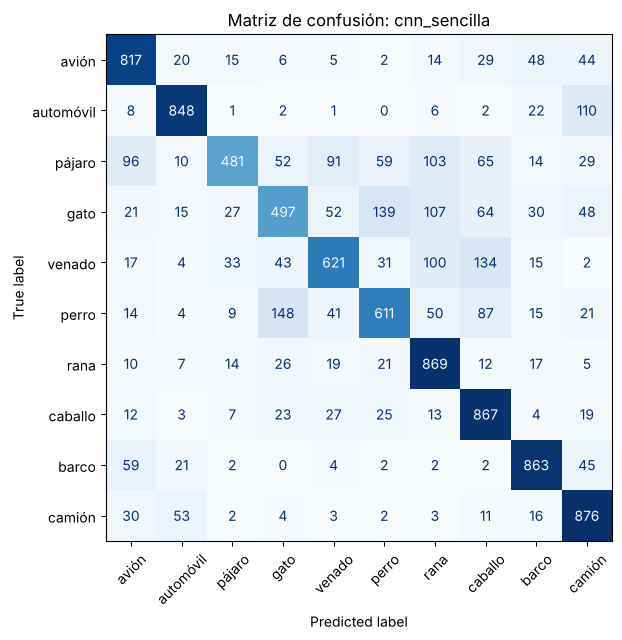

In [13]:
mejor = tabla['exactitud prueba'].idxmax()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix(y_test.ravel(), predicciones[mejor]), display_labels=clases).plot(
    ax=ax, colorbar=False, xticks_rotation=45, cmap='Blues')
ax.set_title(f'Matriz de confusión: {mejor}')
plt.tight_layout(); plt.show()

# Conclusiones.

| Modelo | Parámetros entrenables | Épocas | Tiempo (min) | Exactitud en prueba | Pérdida en prueba |
|---|---|---|---|---|---|
| `cnn_sencilla` | 356,810 | 20 | 13.2 | **0.735** | **0.762** |
| `cnn_profunda` | 305,258 | 15 | 38.8 | 0.733 | 0.838 |
| `vgg16_transfer` | 133,898 (base de 14.7 M congelada) | 14 | 9.1 | 0.659 | 1.036 |

**¿Cuál fue el mejor?** En el conjunto de prueba ganó `cnn_sencilla` (73.5 % de exactitud y la menor pérdida), aunque con una diferencia de apenas 0.2 puntos sobre `cnn_profunda`, que en la práctica es un empate. Si hay que elegir uno con estos resultados me quedo con `cnn_sencilla`, porque logra lo mismo en una tercera parte del tiempo de entrenamiento. Sin embargo, `cnn_profunda` no terminó de aprender: su exactitud de validación seguía subiendo en la última época (74.4 %) y la parada temprana nunca se activó, de modo que el límite de 15 épocas la frenó. `vgg16_transfer` quedó atrás (65.9 %) y su validación se estancó desde la época 5.

**¿Por qué?** Las dos CNN propias se diseñaron para imágenes de 32×32 y aprendieron sus filtros directamente de CIFAR-10; el data augmentation, el Dropout y, en la profunda, la L2 y la normalización por lotes hicieron que la exactitud de validación se mantuviera igual o por encima de la de entrenamiento, es decir, no hubo sobreajuste. VGG16 se entrenó con imágenes de 224×224: al recibir imágenes de 32×32 sus cinco etapas de pooling reducen cada imagen a un solo vector de 512 rasgos, se pierde casi toda la información espacial y, al tener la base congelada, la red no puede adaptar sus filtros al nuevo dominio. En las tres arquitecturas las clases más difíciles fueron gato, pájaro y venado; la matriz de confusión muestra que los errores principales están entre gato y perro, venado y caballo, y automóvil y camión, pares de clases visualmente parecidos.

**¿Qué mejoraría y cómo?**
- Entrenar `cnn_profunda` más épocas (50 o más, con GPU) dejando que la parada temprana decida cuándo detenerse; es la arquitectura con más margen de mejora.
- En transfer learning, redimensionar las imágenes a 96×96 o más antes de la base y hacer *fine-tuning*: descongelar el último bloque convolucional de VGG16 y reentrenarlo con una tasa de aprendizaje baja (1e-5). También probaría bases más eficientes, como ResNet50 o MobileNetV2.
- Usar un programa de tasa de aprendizaje (por ejemplo coseno) y aumentos más fuertes, como *cutout* o *mixup*, para las clases que más se confunden.
- Revisar con Grad-CAM en qué zonas de la imagen se fija cada red al confundir gato con perro, para saber si el problema está en los datos o en la arquitectura.

---
**Nota sobre el uso de inteligencia artificial.** En la resolución de esta práctica utilicé un asistente de inteligencia artificial (Claude, de Anthropic) como apoyo para escribir el código, ejecutar los experimentos y ordenar la redacción. Las decisiones sobre el trabajo, su revisión y la responsabilidad de lo entregado son mías.

*Carlos Eduardo Bustos Hernández*